Файл успешно загружен!
Количество публикаций: 2324

Столбцы:
['date', 'message_id', 'reply_to_msg_id', 'channel_name', 'channel_id', 'sender', 'sender_id', 'message', 'views', 'comments', 'reactions', 'channel_members_count', 'channel_url', 'reactions_total', 'forwarded', 'forwards', 'topic_title']

СТАТИСТИКА ER
Средний ER: 0.71 %
Медианный ER: 0.42 %
Минимальный ER: 0.0 %
Максимальный ER: 7.69 %

ТОП-10 ПУБЛИКАЦИЙ ПО ER


,date,views,reactions_total,comments,forwards,ER
573,2025-10-10 13:11:11+00:00,4822,81,0.0,290,7.693903
572,2025-10-11 12:39:11+00:00,3860,85,2.0,164,6.502591
440,2025-11-10 05:03:13+00:00,3503,191,2.0,32,6.423066
585,2025-10-04 14:12:27+00:00,5327,119,0.0,196,5.913272
880,2025-07-21 12:46:13+00:00,2429,68,0.0,71,5.722520
160,2026-02-23 05:00:58+00:00,3069,150,0.0,22,5.604431
1296,2025-05-08 11:53:39+00:00,667,10,25.0,1,5.397301
842,2025-08-10 20:18:18+00:00,2322,58,0.0,63,5.211025
1955,2025-04-17 14:59:15+00:00,2731,27,0.0,110,5.016477
749,2025-08-23 18:09:41+00:00,2599,65,1.0,59,4.809542


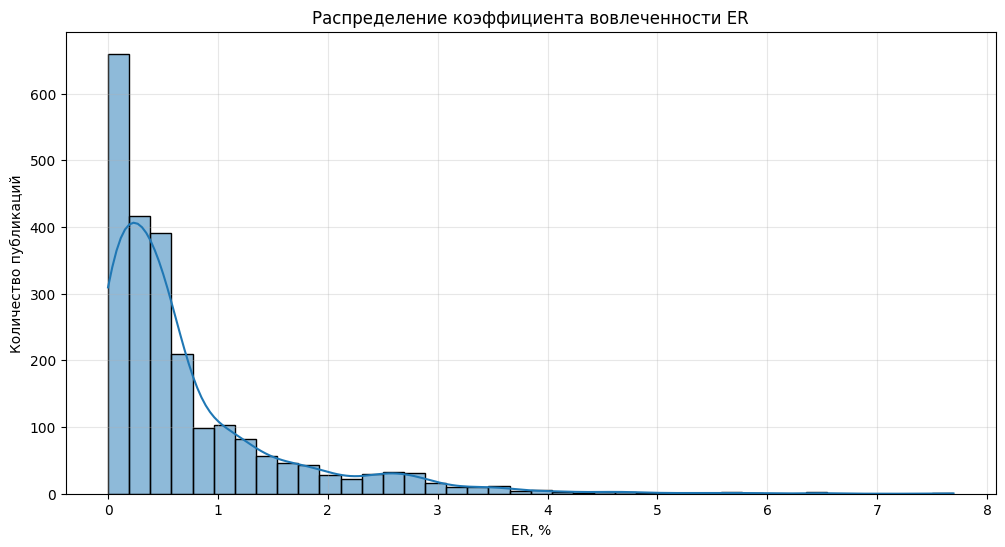

/tmp/ipykernel_516/2529787424.py:115: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df_er['month'] = df_er['date'].dt.to_period('M').astype(str)


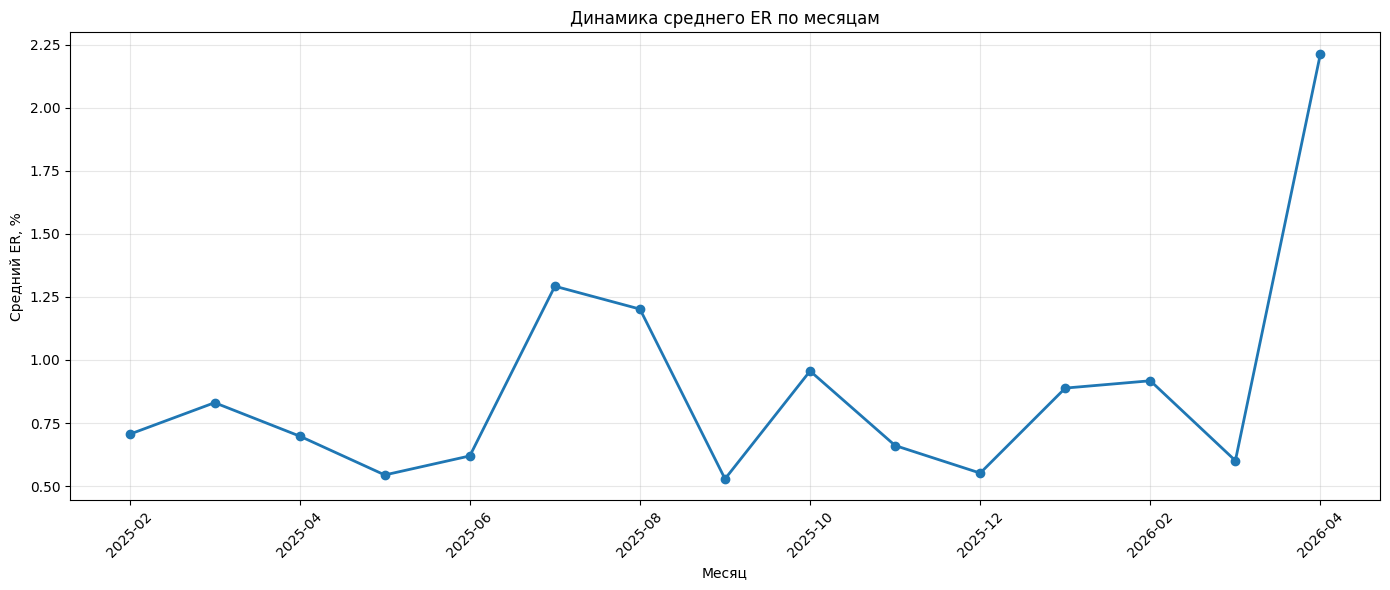


Анализ завершен!
Файл с рассчитанным ER сохранен.


In [ ]:

# ==========================================
# 1. Импорт библиотек
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 2. Загрузка CSV-файла
# ==========================================

file_path = '/content/Messages_Posts.csv'

df = pd.read_csv(
    file_path,
    sep=';',
    encoding='utf-8-sig'
)

print("Файл успешно загружен!")
print("Количество публикаций:", len(df))
print("\nСтолбцы:")
print(df.columns.tolist())

# ==========================================
# 3. Подготовка данных
# ==========================================

columns = ['views', 'comments', 'reactions_total', 'forwards']

for col in columns:
    df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0)

# Убираем публикации с нулевым количеством просмотров
df_er = df[df['views'] > 0].copy()

# ==========================================
# 4. Расчет коэффициента вовлеченности ER
# ==========================================

df_er['ER'] = (
    (df_er['reactions_total'] +
     df_er['comments'] +
     df_er['forwards']) /
    df_er['views']
) * 100

# ==========================================
# 5. Основные статистические показатели
# ==========================================

print("\nСТАТИСТИКА ER")

print("Средний ER:",
      round(df_er['ER'].mean(), 2), "%")

print("Медианный ER:",
      round(df_er['ER'].median(), 2), "%")

print("Минимальный ER:",
      round(df_er['ER'].min(), 2), "%")

print("Максимальный ER:",
      round(df_er['ER'].max(), 2), "%")

# ==========================================
# 6. Топ-10 публикаций по ER
# ==========================================

top_10 = df_er.sort_values(
    by='ER',
    ascending=False
).head(10)

print("\nТОП-10 ПУБЛИКАЦИЙ ПО ER")

display(
    top_10[
        ['date', 'views', 'reactions_total',
         'comments', 'forwards', 'ER']
    ]
)

# ==========================================
# 7. Визуализация распределения ER
# ==========================================

plt.figure(figsize=(12, 6))

sns.histplot(
    df_er['ER'],
    bins=40,
    kde=True
)

plt.title('Распределение коэффициента вовлеченности ER')
plt.xlabel('ER, %')
plt.ylabel('Количество публикаций')

plt.grid(alpha=0.3)
plt.show()

# ==========================================
# 8. Средний ER по месяцам
# ==========================================

df_er['date'] = pd.to_datetime(
    df_er['date'],
    errors='coerce',
    utc=True
)

df_er['month'] = df_er['date'].dt.to_period('M').astype(str)

monthly_er = df_er.groupby('month')['ER'].mean()

plt.figure(figsize=(14, 6))

monthly_er.plot(
    marker='o',
    linewidth=2
)

plt.title('Динамика среднего ER по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Средний ER, %')

plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ==========================================
# 9. Сохранение результатов
# ==========================================

df_er.to_csv(
    '/content/Messages_Posts_with_ER.csv',
    index=False,
    encoding='utf-8-sig'
)

print("\nАнализ завершен!")
print("Файл с рассчитанным ER сохранен.")


Файл загружен!
Количество публикаций: 2324
Количество столбцов: 17

БАЗОВЫЕ ПОКАЗАТЕЛИ
Медиана просмотров: 1353.5
Медиана реакций: 0.0
Медиана пересылок: 5.0

ПОРОГ ВИРУСНОСТИ: 52.72

Количество вирусных публикаций: 117
Количество обычных публикаций: 2207

ТОП-20 ВИРУСНЫХ ПУБЛИКАЦИЙ


,date,message,views,comments,reactions_total,forwards,ER,Viral_Score,Viral_Status
719,2025-08-29 14:07:08+00:00,Дорогие выпускники! Приглашаем вас принять уч...,22681,2.0,23,122,0.648120,100.000000,Вирусная публикация
585,2025-10-04 14:12:27+00:00,Сергей Лебедев поздравил первокурсников Москов...,5327,0.0,119,196,5.913272,81.662038,Вирусная публикация
573,2025-10-10 13:11:11+00:00,Учебный-воспитательный сбор в Московском униве...,4822,0.0,81,290,7.693903,79.863404,Вирусная публикация
700,2025-09-01 14:40:02+00:00,Заместители Министра внутренних дел вручили сл...,4263,4.0,85,47,3.190242,77.107506,Вирусная публикация
572,2025-10-11 12:39:11+00:00,Первая полицейская миля #мосумвд #мосумвдросс...,3860,2.0,85,164,6.502591,75.988515,Вирусная публикация
320,2025-12-31 06:02:47+00:00,С Новым 2026 годом! #мосумвд #мосумвдроссии...,4561,0.0,88,34,2.674852,75.291174,Вирусная публикация
729,2025-08-25 14:19:13+00:00,В Московском областном филиале Университета пр...,3302,0.0,65,55,3.634161,73.398166,Вирусная публикация
457,2025-11-05 07:03:38+00:00,**День откры**тых дверей ** В программе:** вс...,3108,2.0,21,66,2.863578,72.424188,Вирусная публикация
1955,2025-04-17 14:59:15+00:00,🇷🇺**Уважаемые подписчики Telegram-канала! ** ...,2731,0.0,27,110,5.016477,70.403989,Вирусная публикация
440,2025-11-10 05:03:13+00:00,С днём сотрудника органов внутренних дел Росси...,3503,2.0,191,32,6.423066,70.232430,Вирусная публикация


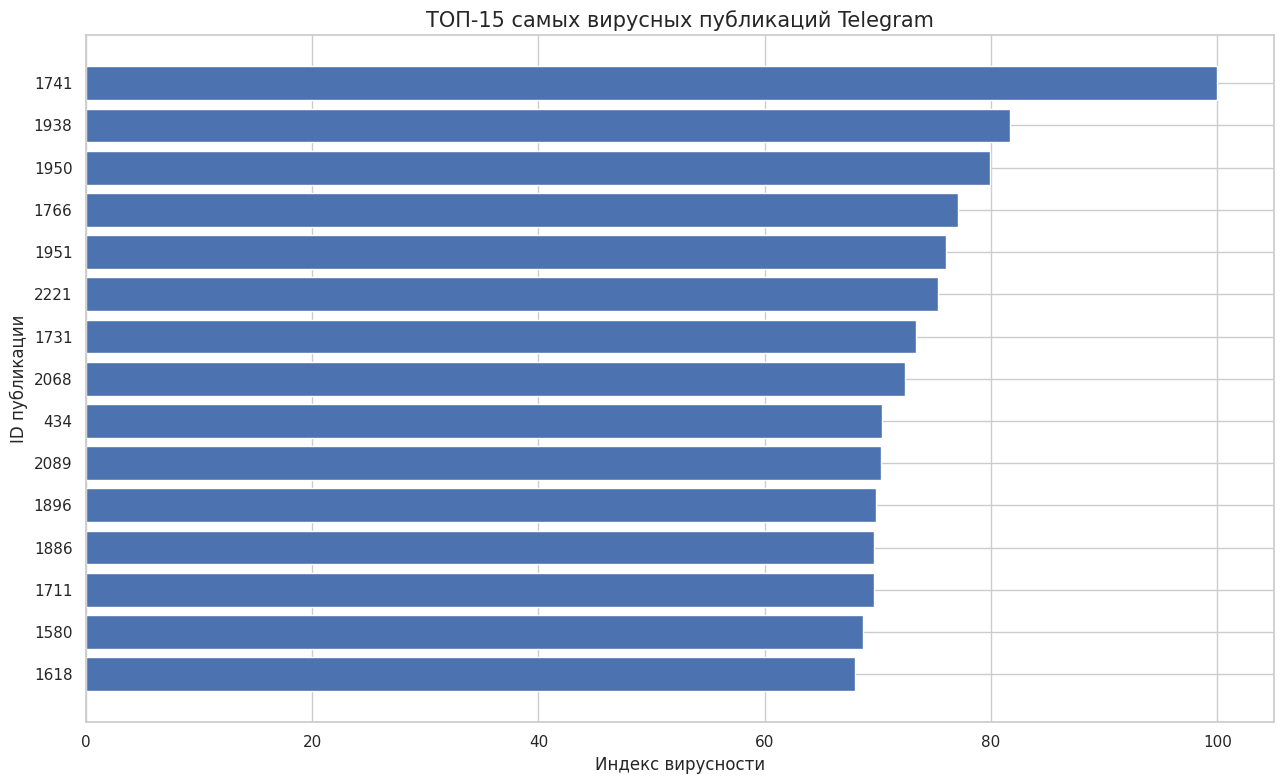

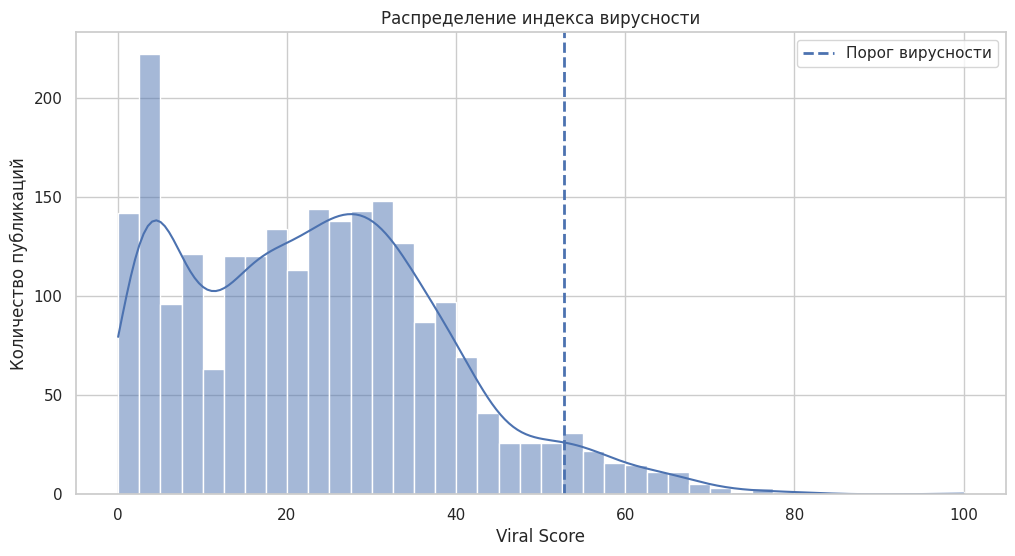


СРАВНЕНИЕ ПУБЛИКАЦИЙ


,views,reactions_total,forwards,ER
Viral_Status,,,,
Вирусная публикация,2887.11,40.86,27.64,2.51
Обычная публикация,1486.92,2.29,6.83,0.61



НАЙДЕННЫЕ АНОМАЛИИ
Количество: 17


,date,message_id,views,reactions_total,forwards,Viral_Score
719,2025-08-29 14:07:08+00:00,1741,22681,23,122,100.000000
585,2025-10-04 14:12:27+00:00,1938,5327,119,196,81.662038
573,2025-10-10 13:11:11+00:00,1950,4822,81,290,79.863404
430,2025-11-11 12:01:41+00:00,2099,4782,0,3,34.614875
431,2025-11-11 12:01:41+00:00,2098,4776,0,3,34.592487
696,2025-09-01 14:40:02+00:00,1770,4748,0,46,53.800323
331,2025-12-20 09:12:35+00:00,2209,4722,0,3,34.390002
695,2025-09-01 14:40:02+00:00,1771,4694,0,42,52.745345
697,2025-09-01 14:40:02+00:00,1769,4654,0,44,53.027962
330,2025-12-20 09:12:35+00:00,2210,4615,0,3,33.983411


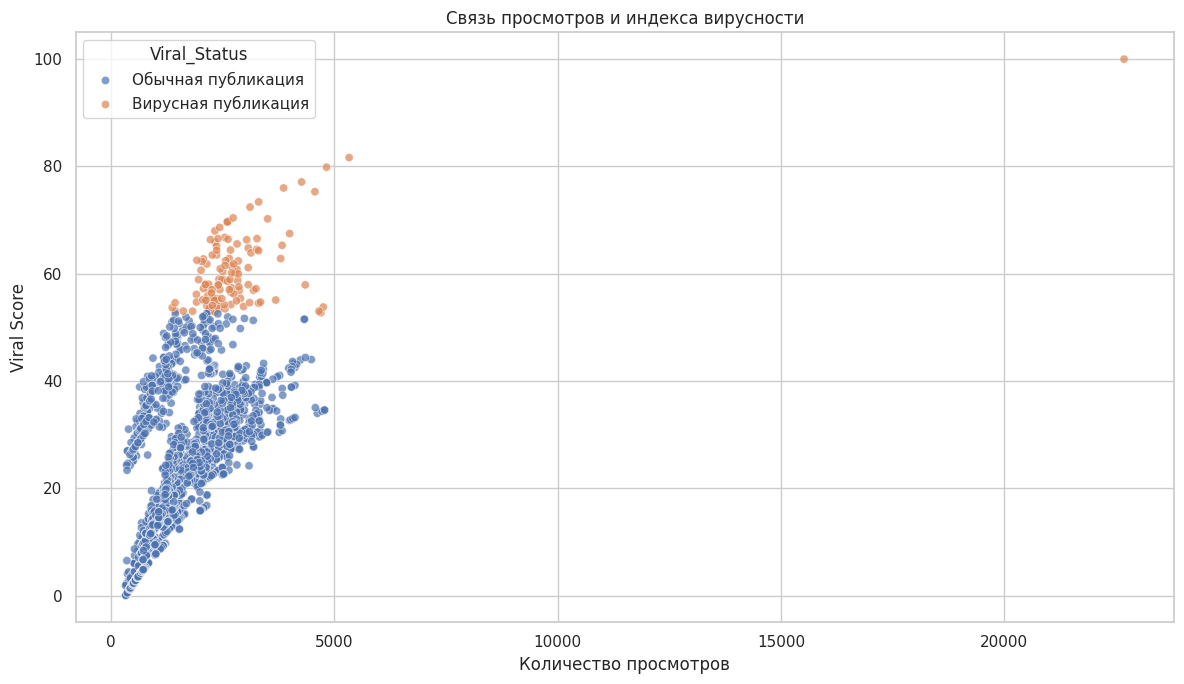


АНАЛИЗ ЗАВЕРШЕН!
Сохранены файлы:
1. Telegram_Viral_Analysis.csv
2. Top_Viral_Posts.csv


In [ ]:

# ============================================================
# ДЕТЕКТОР ВИРУСНЫХ ПУБЛИКАЦИЙ TELEGRAM
# ============================================================

# 1. Импорт библиотек

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.preprocessing import MinMaxScaler

sns.set_theme(style="whitegrid")

# ============================================================
# 2. Загрузка данных
# ============================================================

file_path = '/content/Messages_Posts.csv'

# Пробуем загрузить CSV с разделителем ;
df = pd.read_csv(
    file_path,
    sep=';',
    encoding='utf-8-sig',
    on_bad_lines='warn'
)

print("Файл загружен!")
print("Количество публикаций:", len(df))
print("Количество столбцов:", len(df.columns))

# ============================================================
# 3. Подготовка данных
# ============================================================

numeric_columns = [
    'views',
    'comments',
    'reactions_total',
    'forwards'
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0)

df['date'] = pd.to_datetime(
    df['date'],
    errors='coerce',
    utc=True
)

# Убираем публикации без просмотров
df = df[df['views'] > 0].copy()

# ============================================================
# 4. Расчет базовых показателей
# ============================================================

df['ER'] = (
    (df['reactions_total'] +
     df['comments'] +
     df['forwards']) / df['views']
) * 100

# Медианные показатели канала
median_views = df['views'].median()
median_reactions = df['reactions_total'].median()
median_forwards = df['forwards'].median()

print("\nБАЗОВЫЕ ПОКАЗАТЕЛИ")
print("Медиана просмотров:", median_views)
print("Медиана реакций:", median_reactions)
print("Медиана пересылок:", median_forwards)

# ============================================================
# 5. Индекс вирусности
# ============================================================

# Отношение показателей публикации
# к типичным показателям канала

df['Views_Index'] = df['views'] / max(median_views, 1)

df['Reactions_Index'] = (
    df['reactions_total'] / max(median_reactions, 1)
)

df['Forwards_Index'] = (
    df['forwards'] / max(median_forwards, 1)
)

# Ограничиваем экстремальные значения,
# чтобы единичные выбросы не искажали рейтинг

df['Views_Capped'] = df['Views_Index'].clip(upper=10)
df['Reactions_Capped'] = df['Reactions_Index'].clip(upper=10)
df['Forwards_Capped'] = df['Forwards_Index'].clip(upper=10)

# Логарифмируем показатели
# Это уменьшает влияние экстремальных значений

df['Views_Score'] = np.log1p(df['Views_Capped'])
df['Reactions_Score'] = np.log1p(df['Reactions_Capped'])
df['Forwards_Score'] = np.log1p(df['Forwards_Capped'])

# Нормализация

scaler = MinMaxScaler()

df[['Views_Norm',
    'Reactions_Norm',
    'Forwards_Norm']] = scaler.fit_transform(
    df[['Views_Score',
        'Reactions_Score',
        'Forwards_Score']]
)

# Итоговый индекс вирусности

df['Viral_Score'] = (
    0.50 * df['Views_Norm'] +
    0.25 * df['Reactions_Norm'] +
    0.25 * df['Forwards_Norm']
) * 100

# ============================================================
# 6. Определение вирусных публикаций
# ============================================================

# Используем 95-й процентиль Viral Score

threshold = df['Viral_Score'].quantile(0.95)

df['Viral_Status'] = np.where(
    df['Viral_Score'] >= threshold,
    'Вирусная публикация',
    'Обычная публикация'
)

print("\nПОРОГ ВИРУСНОСТИ:", round(threshold, 2))

print("\nКоличество вирусных публикаций:",
      (df['Viral_Status'] == 'Вирусная публикация').sum())

print("Количество обычных публикаций:",
      (df['Viral_Status'] == 'Обычная публикация').sum())

# ============================================================
# 7. Топ-20 вирусных публикаций
# ============================================================

top_viral = df.sort_values(
    'Viral_Score',
    ascending=False
).head(20)

columns_to_show = [
    'date',
    'views',
    'comments',
    'reactions_total',
    'forwards',
    'ER',
    'Viral_Score',
    'Viral_Status'
]

if 'message' in df.columns:
    columns_to_show.insert(1, 'message')

print("\nТОП-20 ВИРУСНЫХ ПУБЛИКАЦИЙ")

display(top_viral[columns_to_show])

# ============================================================
# 8. График ТОП-15 вирусных публикаций
# ============================================================

top15 = df.nlargest(15, 'Viral_Score').copy()

plt.figure(figsize=(13, 8))

plt.barh(
    top15['message_id'].astype(str),
    top15['Viral_Score']
)

plt.gca().invert_yaxis()

plt.title(
    'ТОП-15 самых вирусных публикаций Telegram',
    fontsize=15
)

plt.xlabel('Индекс вирусности')
plt.ylabel('ID публикации')

plt.tight_layout()
plt.show()

# ============================================================
# 9. Распределение индекса вирусности
# ============================================================

plt.figure(figsize=(12, 6))

sns.histplot(
    df['Viral_Score'],
    bins=40,
    kde=True
)

plt.axvline(
    threshold,
    linestyle='--',
    linewidth=2,
    label='Порог вирусности'
)

plt.title('Распределение индекса вирусности')
plt.xlabel('Viral Score')
plt.ylabel('Количество публикаций')

plt.legend()
plt.show()

# ============================================================
# 10. Сравнение обычных и вирусных публикаций
# ============================================================

comparison = df.groupby('Viral_Status')[
    ['views', 'reactions_total', 'forwards', 'ER']
].mean().round(2)

print("\nСРАВНЕНИЕ ПУБЛИКАЦИЙ")
display(comparison)

# ============================================================
# 11. Поиск аномально популярных публикаций
# ============================================================

# Используем IQR для выявления выбросов по просмотрам

Q1 = df['views'].quantile(0.25)
Q3 = df['views'].quantile(0.75)

IQR = Q3 - Q1

anomaly_threshold = Q3 + 1.5 * IQR

df['Anomaly'] = np.where(
    df['views'] > anomaly_threshold,
    'Аномально высокая популярность',
    'Обычный уровень'
)

anomalies = df[
    df['Anomaly'] == 'Аномально высокая популярность'
].sort_values(
    'views',
    ascending=False
)

print("\nНАЙДЕННЫЕ АНОМАЛИИ")
print("Количество:", len(anomalies))

display(
    anomalies[
        ['date', 'message_id', 'views',
         'reactions_total', 'forwards', 'Viral_Score']
    ].head(20)
)

# ============================================================
# 12. Диаграмма просмотров и вирусности
# ============================================================

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df,
    x='views',
    y='Viral_Score',
    hue='Viral_Status',
    alpha=0.7
)

plt.title('Связь просмотров и индекса вирусности')
plt.xlabel('Количество просмотров')
plt.ylabel('Viral Score')

plt.tight_layout()
plt.show()

# ============================================================
# 13. Сохранение результатов
# ============================================================

df.to_csv(
    '/content/Telegram_Viral_Analysis.csv',
    index=False,
    encoding='utf-8-sig'
)

top_viral.to_csv(
    '/content/Top_Viral_Posts.csv',
    index=False,
    encoding='utf-8-sig'
)

print("\n================================")
print("АНАЛИЗ ЗАВЕРШЕН!")
print("================================")

print("Сохранены файлы:")
print("1. Telegram_Viral_Analysis.csv")
print("2. Top_Viral_Posts.csv")

